# Model Evaluation

Comparison of the best hyperparameterization of each benchmarked model over the 360 PSPLIB projects.

**Benchmarked models (regression problem)**

- Explainable Boosting Machine (`ebm`)
- Random Forest (`rf`)
- XGBoost (`xgb`)
- Support Vector Regression (`sv`)
- Elastic Net (`en`)
- FastAI tabular neural network (`fastai`)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as ss
import scikit_posthocs as sp

In [2]:
sns.set_theme(style="darkgrid")
sns.set_palette("tab10")
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 6)

## Analysis of the model evaluation

The model-selection notebook identified one best LHS configuration per model. Here those six selected models are evaluated on the full set of 360 projects.

For each comparison, projects are treated as blocks and models as repeated treatments. Lower `RelMSE` is better. We apply a Friedman test to evaluate whether all models have equal performance and, when the null hypothesis is rejected, a Conover post-hoc test with Bonferroni correction to inspect pairwise differences.

The analysis is performed once on all 360 projects and then separately for the four PSPLIB subsets: `J120`, `J90`, `J60`, and `J30`.

In [3]:
results_dir = Path("./model_evaluation/results")
hyperparameters_dir = Path("./model_evaluation/hyperparameters")
work_dir = Path("./model_evaluation/analysis")
work_dir.mkdir(parents=True, exist_ok=True)

model_order = ["ebm", "rf", "xgb", "sv", "en", "fastai"]
subset_order = ["J120", "J90", "J60", "J30"]
expected_lhs = {
    "ebm": 24,
    "rf": 14,
    "xgb": 39,
    "sv": 0,
    "en": 36,
    "fastai": 41,
}
model_labels = {model: f"{model}-{lhs}" for model, lhs in expected_lhs.items()}

### Load evaluation results

In [4]:
def load_results(
    results_dir: Path,
    expected_lhs: dict[str, int],
    model_order: list[str],
) -> pd.DataFrame:
    """Load evaluation CSV files and return a clean results table."""

    files = sorted(results_dir.glob("model_evaluation_*_lhs_*_subset_*_project_*.csv"))

    cols = ["project", "subset", "model", "lhs", "RelMSE", "time"]

    results = pd.concat(
        [pd.read_csv(file, usecols=cols) for file in files],
        ignore_index=True,
    )

    results = results.assign(
        project=lambda df: df["project"].astype(str),
        subset=lambda df: df["subset"].astype(str).str.upper(),
        model=lambda df: df["model"].astype(str),
        lhs=lambda df: df["lhs"].astype(int),
        RelMSE=lambda df: pd.to_numeric(df["RelMSE"]),
        time=lambda df: pd.to_numeric(df["time"]),
        model_label=lambda df: df["model"] + "-" + df["model"].map(expected_lhs).astype(str),
    )

    subset_counts = (
        results.groupby(["model", "subset"])
        .size()
        .unstack(fill_value=0)
        .reindex(model_order)
    )

    display(subset_counts)

    return results

results = load_results(results_dir, expected_lhs, model_order)
results.head()

subset,J120,J30,J60,J90
model,,,,
ebm,90,90,90,90
rf,90,90,90,90
xgb,90,90,90,90
sv,90,90,90,90
en,90,90,90,90
fastai,90,90,90,90


,project,subset,model,lhs,RelMSE,time,model_label
0,j12010_6,J120,ebm,24,0.000169,3670.0,ebm-24
1,j12010_7,J120,ebm,24,0.006494,1331.0,ebm-24
2,j12011_2,J120,ebm,24,0.000336,3826.0,ebm-24
3,j12012_3,J120,ebm,24,0.010618,668.0,ebm-24
4,j12012_4,J120,ebm,24,0.000228,2595.0,ebm-24


In [5]:
models = (
    results
    .pivot(index="project", columns="model_label", values="RelMSE")
    .reindex(columns=[model_labels[model] for model in model_order])
)

model_times = (
    results
    .pivot(index="project", columns="model_label", values="time")
    .reindex(columns=[model_labels[model] for model in model_order])
)

project_subsets = (
    results[["project", "subset"]]
    .drop_duplicates()
    .set_index("project")
    .loc[models.index]
)

print(f"Projects: {models.shape[0]}")
print(f"Models: {models.shape[1]}")
print(f"Missing RelMSE values: {int(models.isna().sum().sum())}")
print(f"Missing time values: {int(model_times.isna().sum().sum())}")
models.head()

Projects: 360
Models: 6
Missing RelMSE values: 0
Missing time values: 0


model_label,ebm-24,rf-14,xgb-39,sv-0,en-36,fastai-41
project,,,,,,
j12010_6,0.000169,0.207629,0.013536,0.017817,1.450210e-06,0.007987
j12010_7,0.006494,0.216327,0.017502,0.021936,5.129469e-03,0.018187
j12011_2,0.000336,0.213010,0.015380,0.018108,1.514181e-04,0.013111
j12012_3,0.010618,0.221843,0.022529,0.026371,8.159041e-03,0.011660
j12012_4,0.000228,0.235109,0.017539,0.017296,2.138649e-07,0.003310


### Statistical comparison function

In [6]:
def summarize_model_performance(data: pd.DataFrame) -> pd.DataFrame:
    """Summarize RelMSE and rank-based performance. Lower is better."""

    clean = data.dropna()
    ranks = clean.rank(axis=1, ascending=True, method="average")

    summary = pd.DataFrame({
        "mean_rank": ranks.mean(),
        "median_rank": ranks.median(),
        "std_rank": ranks.std(),
        "mean_RelMSE": clean.mean(),
        "median_RelMSE": clean.median(),
        "std_RelMSE": clean.std(),
        "wins": clean.idxmin(axis=1).value_counts(),
    })

    summary["wins"] = summary["wins"].fillna(0).astype(int)

    return (
        summary
        .sort_values(["mean_rank", "mean_RelMSE"])
        .rename_axis("model")
        .reset_index()
    )


def model_comparison(
    data: pd.DataFrame,
    label: str,
    significance: float = 0.05,
    p_adjust: str = "bonferroni",
    figsize: tuple[int, int] = (12, 4),
    plot: bool = True,
) -> dict:
    """Run Friedman and Conover tests for a complete project x model matrix."""

    clean = data.dropna()

    ranks = clean.rank(axis=1, ascending=True, method="average")
    avg_rank = ranks.mean().sort_values()
    best_model = avg_rank.index[0]

    friedman = ss.friedmanchisquare(
        *[clean[col].to_numpy() for col in clean.columns]
    )

    print(f"{label}: {clean.shape[0]} projects x {clean.shape[1]} models")
    print(f"Friedman's test statistic: {friedman.statistic:.6g}")
    print(f"Friedman's test p-value: {friedman.pvalue:.6g}")
    print(f"Best model by average rank: {best_model}")

    result = {
        "label": label,
        "n_projects": clean.shape[0],
        "n_models": clean.shape[1],
        "best_model": best_model,
        "avg_rank": avg_rank,
        "friedman_statistic": friedman.statistic,
        "friedman_pvalue": friedman.pvalue,
        "conover_test": None,
        "best_group": [best_model],
    }

    if friedman.pvalue >= significance:
        print("Do not reject null hypothesis that all models perform equally.")
        return result

    print("Reject null hypothesis that all models perform equally.")
    print(f"Conover post-hoc test for all model pairs ({p_adjust} correction).")

    conover = sp.posthoc_conover_friedman(clean, p_adjust=p_adjust)
    conover = conover.loc[avg_rank.index, avg_rank.index]

    best_group = (
        conover.loc[best_model]
        .loc[lambda p: p >= significance]
        .index
    )
    best_group = avg_rank.loc[best_group].sort_values().index.tolist()

    result["conover_test"] = conover
    result["best_group"] = best_group

    display(conover)

    if plot:
        plt.figure(figsize=figsize)
        plt.title(f"Critical difference diagram - {label}")
        sp.critical_difference_diagram(avg_rank, conover)
        plt.show()

    print(f"Models not significantly different from the best: {best_group}")

    return result

def pareto_frontier(summary: pd.DataFrame) -> pd.DataFrame:
    """Mark non-dominated models. Lower median_RelMSE and median_time are better."""

    values = summary[["median_RelMSE", "median_time"]].to_numpy()

    dominated = (
        (values[:, None, 0] >= values[None, :, 0])
        & (values[:, None, 1] >= values[None, :, 1])
        & (
            (values[:, None, 0] > values[None, :, 0])
            | (values[:, None, 1] > values[None, :, 1])
        )
    ).any(axis=1)

    summary = summary.copy()
    summary["pareto_frontier"] = ~dominated

    return summary

def summarize_accuracy_time(
    relmse_data: pd.DataFrame,
    time_data: pd.DataFrame,
    relmse_weight: float = 0.8,
) -> pd.DataFrame:
    """Summarize the trade-off between predictive error and computational time."""

    relmse = relmse_data.dropna()
    times = time_data.loc[relmse.index]

    relmse_ranks = relmse.rank(axis=1, ascending=True, method="average")
    time_ranks = times.rank(axis=1, ascending=True, method="average")

    time_weight = 1 - relmse_weight
    tradeoff_rank = (
        relmse_weight * relmse_ranks.mean()
        + time_weight * time_ranks.mean()
    )

    summary = pd.DataFrame({
        "mean_RelMSE": relmse.mean(),
        "median_RelMSE": relmse.median(),
        "mean_time": times.mean(),
        "median_time": times.median(),
        "mean_RelMSE_rank": relmse_ranks.mean(),
        "mean_time_rank": time_ranks.mean(),
        "tradeoff_rank": tradeoff_rank,
        "tradeoff_rank_80_20": 0.8 * relmse_ranks.mean() + 0.2 * time_ranks.mean(),
        "tradeoff_rank_50_50": 0.5 * relmse_ranks.mean() + 0.5 * time_ranks.mean(),
        "error_wins": relmse.idxmin(axis=1).value_counts(),
        "time_wins": times.idxmin(axis=1).value_counts(),
    })

    summary[["error_wins", "time_wins"]] = (
        summary[["error_wins", "time_wins"]]
        .fillna(0)
        .astype(int)
    )

    summary = pareto_frontier(summary)

    return (
        summary
        .sort_values(["tradeoff_rank", "mean_RelMSE_rank", "mean_time_rank"])
        .rename_axis("model")
        .reset_index()
    )


def plot_accuracy_time(
    tradeoff_summary: pd.DataFrame,
    label: str,
    figsize: tuple[int, int] = (8, 5),
) -> None:
    """Plot median computational time against median RelMSE."""

    plt.figure(figsize=figsize)

    ax = sns.scatterplot(
        data=tradeoff_summary,
        x="median_time",
        y="median_RelMSE",
        hue="pareto_frontier",
        style="pareto_frontier",
        s=120,
    )

    for row in tradeoff_summary.itertuples():
        ax.annotate(
            row.model,
            (row.median_time, row.median_RelMSE),
            xytext=(6, 4),
            textcoords="offset points",
            fontsize=9,
        )

    ax.set_title(f"Accuracy vs computational time - {label}")
    ax.set_xlabel("Median computational time")
    ax.set_ylabel("Median RelMSE")
    ax.legend(title="Pareto frontier")

    plt.show()

## Global comparison over the 360 projects

In [7]:
global_summary = summarize_model_performance(models)
global_summary

,model,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,std_RelMSE,wins
0,en-36,1.727778,1.0,1.025201,0.012385,0.001655,0.020078,206
1,ebm-24,2.088889,2.0,0.665830,0.013464,0.001389,0.025895,48
2,fastai-41,2.600000,3.0,1.213205,0.010785,0.007768,0.008999,104
3,xgb-39,3.997222,4.0,0.682036,0.027138,0.016280,0.030716,1
4,sv-0,4.591667,5.0,0.681991,0.030844,0.023940,0.025021,1
5,rf-14,5.994444,6.0,0.105409,0.179460,0.178584,0.081897,0


All projects: 360 projects x 6 models
Friedman's test statistic: 1399.19
Friedman's test p-value: 2.06328e-300
Best model by average rank: en-36
Reject null hypothesis that all models perform equally.
Conover post-hoc test for all model pairs (bonferroni correction).
Models not significantly different from the best: ['en-36']


model_label,en-36,ebm-24,fastai-41,xgb-39,sv-0,rf-14
model_label,,,,,,
en-36,1.000000e+00,7.270395e-07,4.675871e-37,8.013327e-199,2.199632e-281,0.000000e+00
ebm-24,7.270395e-07,1.000000e+00,2.175553e-13,1.797312e-150,5.159154e-231,0.000000e+00
fastai-41,4.675871e-37,2.175553e-13,1.000000e+00,4.663067e-88,2.083761e-161,0.000000e+00
xgb-39,8.013327e-199,1.797312e-150,4.663067e-88,1.000000e+00,6.970378e-18,3.839371e-162
sv-0,2.199632e-281,5.159154e-231,2.083761e-161,6.970378e-18,1.000000e+00,1.110858e-88
rf-14,0.000000e+00,0.000000e+00,0.000000e+00,3.839371e-162,1.110858e-88,1.000000e+00


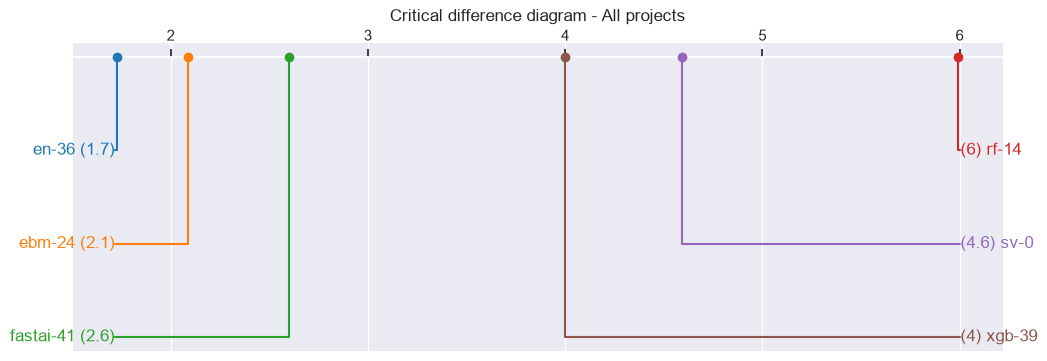

In [8]:
global_comparison = model_comparison(models, label="All projects")

## Accuracy vs computational time

This section complements the statistical comparison based on `RelMSE`. It compares predictive performance against the computational time required to fit and test each model. Lower values are better in both dimensions.

The `tradeoff_rank_80_20` score prioritizes error over time, while `tradeoff_rank_50_50` gives both criteria the same weight. The Pareto frontier marks models that are not dominated by another model with both lower error and lower time.

In [9]:
global_tradeoff_summary = summarize_accuracy_time(models, model_times)
global_tradeoff_summary

,model,mean_RelMSE,median_RelMSE,mean_time,median_time,mean_RelMSE_rank,mean_time_rank,tradeoff_rank,tradeoff_rank_80_20,tradeoff_rank_50_50,error_wins,time_wins,pareto_frontier
0,en-36,0.012385,0.001655,651.941667,61.0,1.727778,3.883333,2.158889,2.158889,2.805556,206,0,True
1,fastai-41,0.010785,0.007768,60.288889,59.0,2.600000,3.462500,2.772500,2.772500,3.031250,104,0,True
2,ebm-24,0.013464,0.001389,1089.672222,724.0,2.088889,5.708333,2.812778,2.812778,3.898611,48,0,True
3,xgb-39,0.027138,0.016280,2.813889,3.0,3.997222,1.025000,3.402778,3.402778,2.511111,1,360,True
4,sv-0,0.030844,0.023940,16.358333,15.0,4.591667,2.234722,4.120278,4.120278,3.413194,1,0,False
5,rf-14,0.179460,0.178584,277.997222,256.0,5.994444,4.686111,5.732778,5.732778,5.340278,0,0,False


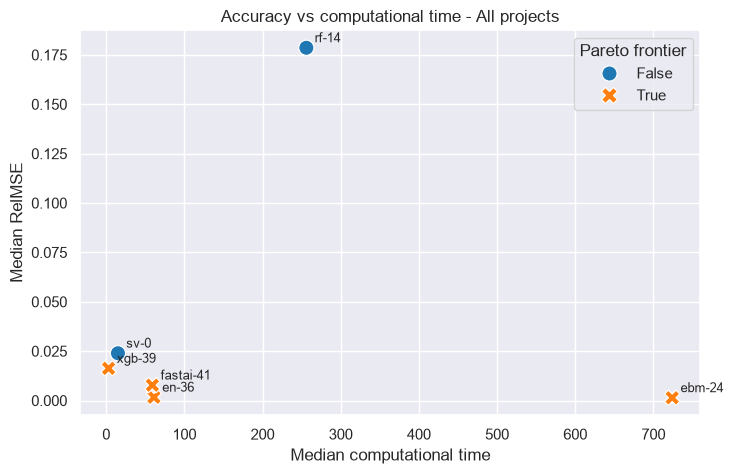

In [10]:
plot_accuracy_time(global_tradeoff_summary, label="All projects")

## Comparison by project subset

Subset J120
Subset J120: 90 projects x 6 models
Friedman's test statistic: 379.022
Friedman's test p-value: 9.83148e-80
Best model by average rank: en-36
Reject null hypothesis that all models perform equally.
Conover post-hoc test for all model pairs (bonferroni correction).
Models not significantly different from the best: ['en-36']
Accuracy-time trade-off for subset J120
Subset J90
Subset J90: 90 projects x 6 models
Friedman's test statistic: 382.019
Friedman's test p-value: 2.22316e-80
Best model by average rank: en-36
Reject null hypothesis that all models perform equally.
Conover post-hoc test for all model pairs (bonferroni correction).
Models not significantly different from the best: ['en-36']
Accuracy-time trade-off for subset J90
Subset J60
Subset J60: 90 projects x 6 models
Friedman's test statistic: 375.073
Friedman's test p-value: 6.97254e-79
Best model by average rank: en-36
Reject null hypothesis that all models perform equally.
Conover post-hoc test for all model pairs

,model,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,std_RelMSE,wins
0,en-36,1.511111,1.0,0.690944,0.014533,0.003629,0.024313,54
1,ebm-24,2.244444,2.0,0.546924,0.019142,0.004108,0.034756,4
2,fastai-41,2.388889,3.0,1.158209,0.012047,0.009384,0.009777,32
3,xgb-39,4.400000,4.0,0.576701,0.038752,0.021863,0.040202,0
4,sv-0,4.455556,4.5,0.583694,0.037943,0.019670,0.038014,0
5,rf-14,6.000000,6.0,0.000000,0.254773,0.240990,0.060315,0


model_label,en-36,ebm-24,fastai-41,xgb-39,sv-0,rf-14
model_label,,,,,,
en-36,1.000000e+00,1.938722e-09,3.784667e-13,7.378329e-90,4.288517e-92,1.978931e-149
ebm-24,1.938722e-09,1.000000e+00,1.000000e+00,8.184706e-60,4.251160e-62,1.846772e-123
fastai-41,3.784667e-13,1.000000e+00,1.000000e+00,6.702822e-54,3.610914e-56,4.551232e-118
xgb-39,7.378329e-90,8.184706e-60,6.702822e-54,1.000000e+00,1.000000e+00,1.535647e-37
sv-0,4.288517e-92,4.251160e-62,3.610914e-56,1.000000e+00,1.000000e+00,2.035640e-35
rf-14,1.978931e-149,1.846772e-123,4.551232e-118,1.535647e-37,2.035640e-35,1.000000e+00


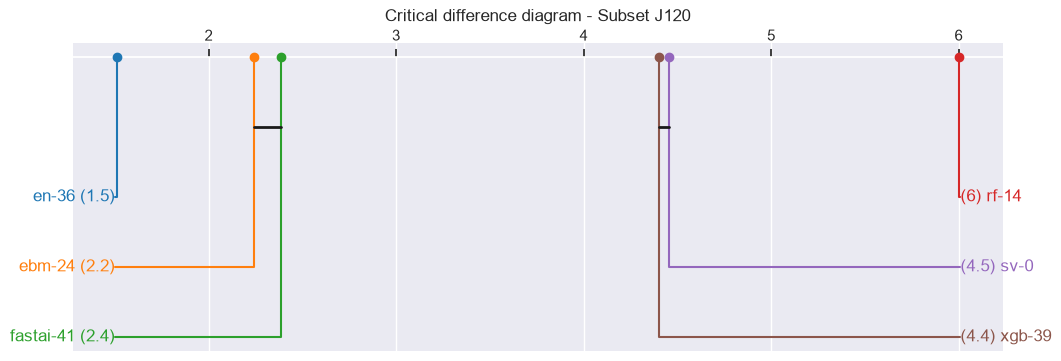

,model,mean_RelMSE,median_RelMSE,mean_time,median_time,mean_RelMSE_rank,mean_time_rank,tradeoff_rank,tradeoff_rank_80_20,tradeoff_rank_50_50,error_wins,time_wins,pareto_frontier
0,en-36,0.014533,0.003629,1480.455556,471.5,1.511111,4.733333,2.155556,2.155556,3.122222,54,0,True
1,fastai-41,0.012047,0.009384,61.711111,60.0,2.388889,3.177778,2.546667,2.546667,2.783333,32,0,True
2,ebm-24,0.019142,0.004108,1933.733333,1586.5,2.244444,5.555556,2.906667,2.906667,3.900000,4,0,False
3,xgb-39,0.038752,0.021863,4.744444,5.0,4.400000,1.000000,3.720000,3.720000,2.700000,0,90,True
4,sv-0,0.037943,0.019670,21.733333,22.0,4.455556,2.033333,3.971111,3.971111,3.244444,0,0,True
5,rf-14,0.254773,0.240990,451.200000,473.5,6.000000,4.500000,5.700000,5.700000,5.250000,0,0,False


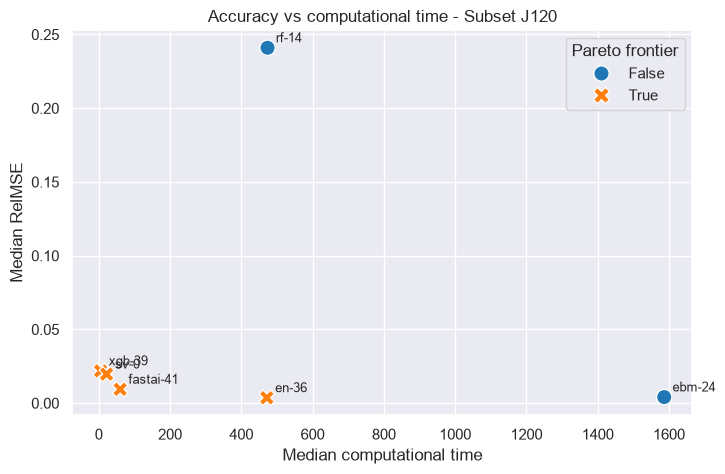

,model,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,std_RelMSE,wins
0,en-36,1.700000,1.0,0.840679,0.014785,0.005664,0.020508,49
1,ebm-24,2.177778,2.0,0.572355,0.016218,0.005821,0.025525,6
2,fastai-41,2.211111,3.0,1.065226,0.010291,0.007445,0.007537,35
3,xgb-39,4.200000,4.0,0.501683,0.034693,0.020973,0.031251,0
4,sv-0,4.711111,5.0,0.502677,0.036160,0.026194,0.023163,0
5,rf-14,6.000000,6.0,0.000000,0.224066,0.217986,0.050244,0


model_label,en-36,ebm-24,fastai-41,xgb-39,sv-0,rf-14
model_label,,,,,,
en-36,1.000000e+00,2.191654e-04,5.486985e-05,3.078505e-76,2.220820e-97,3.410830e-146
ebm-24,2.191654e-04,1.000000e+00,1.000000e+00,3.732650e-56,1.232127e-77,5.789322e-129
fastai-41,5.486985e-05,1.000000e+00,1.000000e+00,9.201277e-55,3.078505e-76,1.008547e-127
xgb-39,3.078505e-76,3.732650e-56,9.201277e-55,1.000000e+00,5.486985e-05,5.982795e-47
sv-0,2.220820e-97,1.232127e-77,3.078505e-76,5.486985e-05,1.000000e+00,4.571768e-27
rf-14,3.410830e-146,5.789322e-129,1.008547e-127,5.982795e-47,4.571768e-27,1.000000e+00


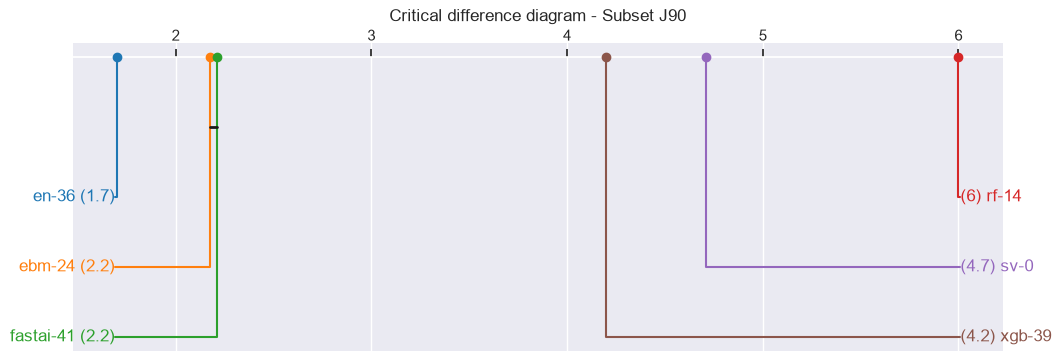

,model,mean_RelMSE,median_RelMSE,mean_time,median_time,mean_RelMSE_rank,mean_time_rank,tradeoff_rank,tradeoff_rank_80_20,tradeoff_rank_50_50,error_wins,time_wins,pareto_frontier
0,en-36,0.014785,0.005664,890.900000,413.0,1.700000,4.683333,2.296667,2.296667,3.191667,49,0,True
1,fastai-41,0.010291,0.007445,62.200000,60.0,2.211111,3.283333,2.425556,2.425556,2.747222,35,0,True
2,ebm-24,0.016218,0.005821,1333.333333,1009.5,2.177778,5.533333,2.848889,2.848889,3.855556,6,0,False
3,xgb-39,0.034693,0.020973,3.433333,3.0,4.200000,1.000000,3.560000,3.560000,2.600000,0,90,True
4,sv-0,0.036160,0.026194,17.577778,17.0,4.711111,2.033333,4.175556,4.175556,3.372222,0,0,False
5,rf-14,0.224066,0.217986,329.277778,342.5,6.000000,4.466667,5.693333,5.693333,5.233333,0,0,False


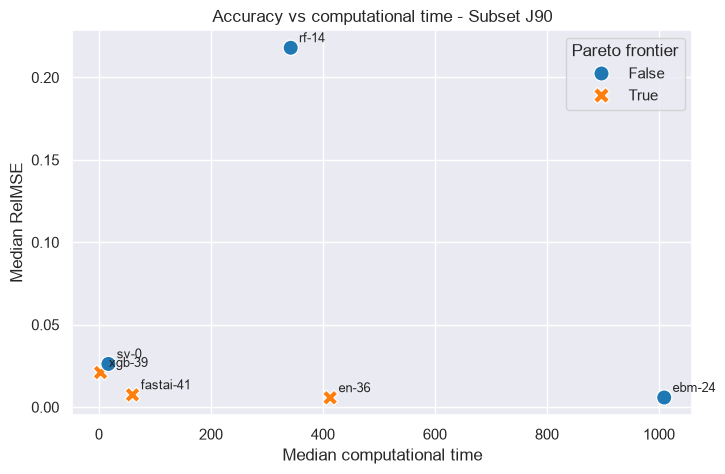

,model,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,std_RelMSE,wins
0,en-36,1.600000,1.0,0.790392,0.010772,0.001162,0.017747,52
1,ebm-24,1.977778,2.0,0.702768,0.011533,0.000880,0.023132,18
2,fastai-41,2.733333,3.0,1.129781,0.010751,0.007918,0.009706,20
3,xgb-39,3.900000,4.0,0.520372,0.023250,0.013655,0.024759,0
4,sv-0,4.788889,5.0,0.529881,0.032922,0.026581,0.014045,0
5,rf-14,6.000000,6.0,0.000000,0.160769,0.156789,0.040814,0


model_label,en-36,ebm-24,fastai-41,xgb-39,sv-0,rf-14
model_label,,,,,,
en-36,1.000000e+00,1.560443e-02,7.478377e-20,3.149629e-63,1.893353e-98,2.336440e-142
ebm-24,1.560443e-02,1.000000e+00,1.732465e-09,3.213630e-48,1.157506e-83,2.675205e-129
fastai-41,7.478377e-20,1.732465e-09,1.000000e+00,6.725191e-21,1.788251e-53,1.936951e-101
xgb-39,3.149629e-63,3.213630e-48,6.725191e-21,1.000000e+00,8.358520e-13,3.075939e-55
sv-0,1.893353e-98,1.157506e-83,1.788251e-53,8.358520e-13,1.000000e+00,2.539444e-22
rf-14,2.336440e-142,2.675205e-129,1.936951e-101,3.075939e-55,2.539444e-22,1.000000e+00


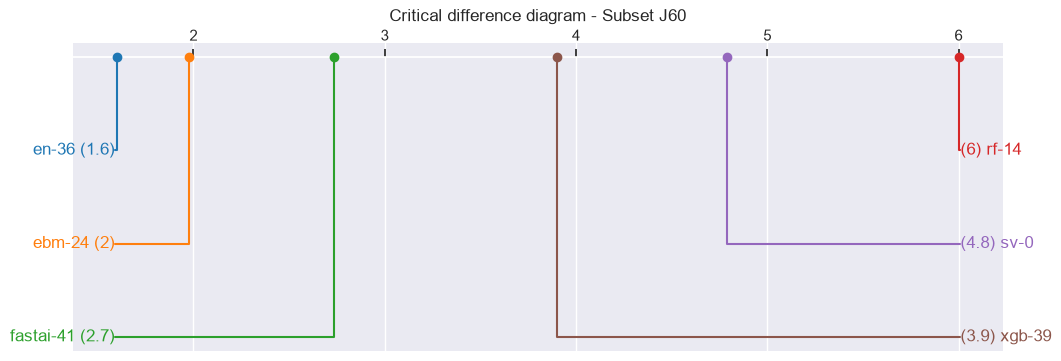

,model,mean_RelMSE,median_RelMSE,mean_time,median_time,mean_RelMSE_rank,mean_time_rank,tradeoff_rank,tradeoff_rank_80_20,tradeoff_rank_50_50,error_wins,time_wins,pareto_frontier
0,en-36,0.010772,0.001162,210.500000,36.5,1.600000,3.650000,2.010000,2.010000,2.625000,52,0,True
1,ebm-24,0.011533,0.000880,741.055556,613.5,1.977778,5.788889,2.740000,2.740000,3.883333,18,0,True
2,fastai-41,0.010751,0.007918,60.122222,59.0,2.733333,3.533333,2.893333,2.893333,3.133333,20,0,False
3,xgb-39,0.023250,0.013655,2.077778,2.0,3.900000,1.000000,3.320000,3.320000,2.450000,0,90,True
4,sv-0,0.032922,0.026581,14.888889,15.0,4.788889,2.250000,4.281111,4.281111,3.519444,0,0,False
5,rf-14,0.160769,0.156789,223.422222,231.0,6.000000,4.777778,5.755556,5.755556,5.388889,0,0,False


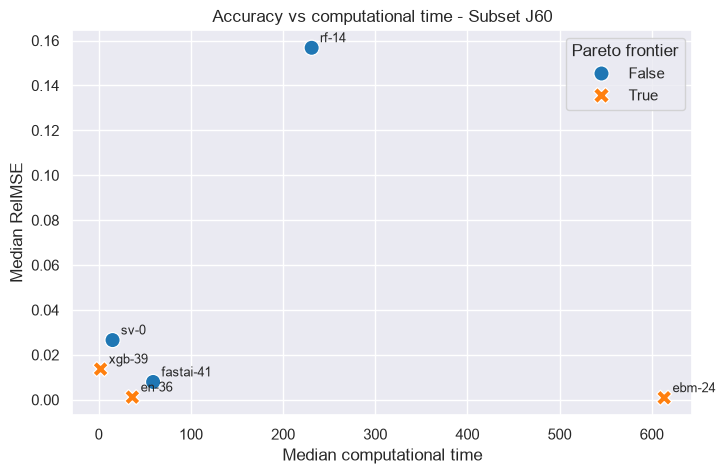

,model,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,std_RelMSE,wins
0,ebm-24,1.955556,2.0,0.777653,0.006962,0.000258,0.014947,20
1,en-36,2.100000,1.0,1.491926,0.009449,0.000459,0.016661,51
2,fastai-41,3.066667,3.0,1.322238,0.010051,0.006435,0.008811,17
3,xgb-39,3.488889,4.0,0.738119,0.011857,0.007216,0.012426,1
4,sv-0,4.411111,5.0,0.946839,0.016352,0.014064,0.007076,1
5,rf-14,5.977778,6.0,0.210819,0.078234,0.078820,0.027630,0


model_label,ebm-24,en-36,fastai-41,xgb-39,sv-0,rf-14
model_label,,,,,,
ebm-24,1.000000e+00,1.000000e+00,6.208135e-10,7.000618e-18,4.314617e-40,2.291401e-83
en-36,1.000000e+00,1.000000e+00,1.156678e-07,5.840701e-15,2.607051e-36,2.303250e-79
fastai-41,6.208135e-10,1.156678e-07,1.000000e+00,1.566322e-01,4.217894e-14,1.986866e-52
xgb-39,7.000618e-18,5.840701e-15,1.566322e-01,1.000000e+00,5.136266e-07,5.643350e-41
sv-0,4.314617e-40,2.607051e-36,4.217894e-14,5.136266e-07,1.000000e+00,1.393184e-18
rf-14,2.291401e-83,2.303250e-79,1.986866e-52,5.643350e-41,1.393184e-18,1.000000e+00


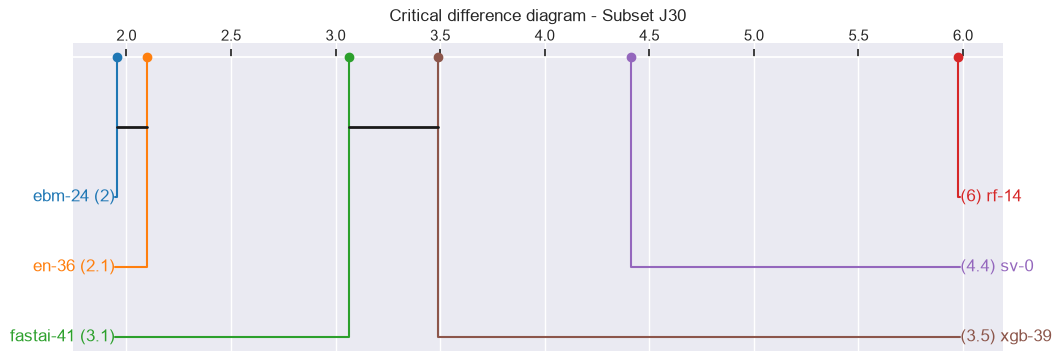

,model,mean_RelMSE,median_RelMSE,mean_time,median_time,mean_RelMSE_rank,mean_time_rank,tradeoff_rank,tradeoff_rank_80_20,tradeoff_rank_50_50,error_wins,time_wins,pareto_frontier
0,en-36,0.009449,0.000459,25.911111,5.0,2.100000,2.466667,2.173333,2.173333,2.283333,51,0,True
1,ebm-24,0.006962,0.000258,350.566667,282.5,1.955556,5.955556,2.755556,2.755556,3.955556,20,0,True
2,xgb-39,0.011857,0.007216,1.000000,1.0,3.488889,1.100000,3.011111,3.011111,2.294444,1,90,True
3,fastai-41,0.010051,0.006435,57.122222,57.5,3.066667,3.855556,3.224444,3.224444,3.461111,17,0,False
4,sv-0,0.016352,0.014064,11.233333,11.0,4.411111,2.622222,4.053333,4.053333,3.516667,1,0,False
5,rf-14,0.078234,0.078820,108.088889,107.5,5.977778,5.000000,5.782222,5.782222,5.488889,0,0,False


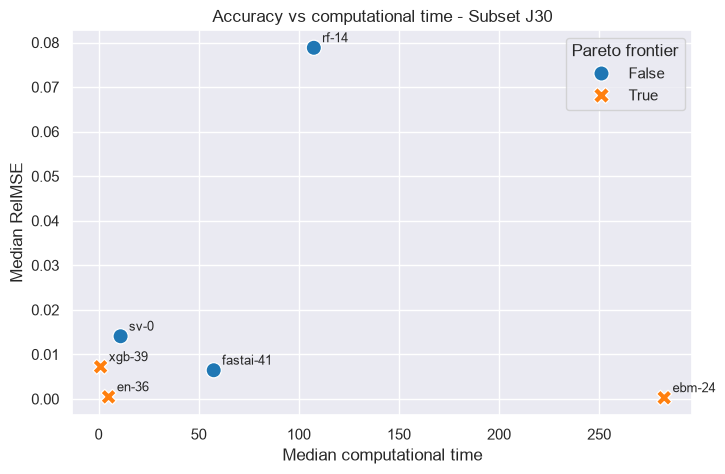

In [11]:
subset_summaries = {}
subset_comparisons = {}
subset_tradeoff_summaries = {}

for subset in subset_order:
    subset_projects = project_subsets.index[project_subsets["subset"].eq(subset)]
    subset_data = models.loc[subset_projects]
    subset_time_data = model_times.loc[subset_projects]

    print("=" * 80)
    print(f"Subset {subset}")
    display(summarize_model_performance(subset_data))

    subset_summaries[subset] = summarize_model_performance(subset_data)
    subset_comparisons[subset] = model_comparison(
        subset_data,
        label=f"Subset {subset}",
        figsize=(12, 4),
    )

    print(f"Accuracy-time trade-off for subset {subset}")
    subset_tradeoff_summaries[subset] = summarize_accuracy_time(subset_data, subset_time_data)
    display(subset_tradeoff_summaries[subset])
    plot_accuracy_time(subset_tradeoff_summaries[subset], label=f"Subset {subset}")

## Consolidated Friedman results

In [12]:
friedman_results = pd.DataFrame([
    {
        "scope": "All",
        "n_projects": global_comparison["n_projects"],
        "best_model": global_comparison["best_model"],
        #"friedman_statistic": global_comparison["friedman_statistic"],
        "friedman_pvalue": global_comparison["friedman_pvalue"],
        "best_group": ", ".join(global_comparison["best_group"]),
    },
    *[
        {
            "scope": subset,
            "n_projects": comparison["n_projects"],
            "best_model": comparison["best_model"],
            #"friedman_statistic": comparison["friedman_statistic"],
            "friedman_pvalue": comparison["friedman_pvalue"],
            "best_group": ", ".join(comparison["best_group"]),
        }
        for subset, comparison in subset_comparisons.items()
    ],
])

friedman_results

,scope,n_projects,best_model,friedman_pvalue,best_group
0,All,360,en-36,2.063276e-300,en-36
1,J120,90,en-36,9.831481e-80,en-36
2,J90,90,en-36,2.223157e-80,en-36
3,J60,90,en-36,6.972540e-79,en-36
4,J30,90,ebm-24,8.071818e-62,"ebm-24, en-36"


## Save analysis tables

In [13]:
global_summary.to_csv(work_dir / "model_comparison_summary_all.csv", index=False)
global_tradeoff_summary.to_csv(work_dir / "accuracy_time_tradeoff_all.csv", index=False)
friedman_results.to_csv(work_dir / "friedman_results_all_and_subsets.csv", index=False)

for subset, summary in subset_summaries.items():
    summary.to_csv(work_dir / f"model_comparison_summary_{subset.lower()}.csv", index=False)

for subset, summary in subset_tradeoff_summaries.items():
    summary.to_csv(work_dir / f"accuracy_time_tradeoff_{subset.lower()}.csv", index=False)

if global_comparison["conover_test"] is not None:
    global_comparison["conover_test"].to_csv(work_dir / "conover_all.csv")

for subset, comparison in subset_comparisons.items():
    if comparison["conover_test"] is not None:
        comparison["conover_test"].to_csv(work_dir / f"conover_{subset.lower()}.csv")

## Bootstrap uncertainty over project-level results

The following cells quantify uncertainty and practical effect sizes without retraining any model. The bootstrap unit is the project: each replicate samples projects with replacement and preserves the paired `RelMSE` values of all models for each sampled project.

In [14]:
from itertools import combinations

BOOTSTRAP_SEED = 112358
N_BOOTSTRAP = 10_000
CI_LEVEL = 0.95


def percentile_ci(values, ci_level=CI_LEVEL):
    """Percentile confidence interval."""
    alpha = 1 - ci_level
    return np.quantile(values, [alpha / 2, 1 - alpha / 2])

def paired_dominance(a, b):
    """Dominance effect size for paired losses. Positive values favor a."""
    delta = np.asarray(a) - np.asarray(b)
    wins = np.sum(delta < 0)
    losses = np.sum(delta > 0)
    denom = wins + losses
    return np.nan if denom == 0 else (wins - losses) / denom

def bootstrap_model_summary(
    data,
    n_bootstrap=N_BOOTSTRAP,
    seed=BOOTSTRAP_SEED,
    ci_level=CI_LEVEL,
):
    """Bootstrap model-level mean, median, and rank summaries over projects."""

    clean = data.dropna()
    values = clean.to_numpy()
    models = clean.columns

    rng = np.random.default_rng(seed)
    n_projects = len(clean)
    sample_idx = rng.integers(0, n_projects, size=(n_bootstrap, n_projects))

    ranks = clean.rank(axis=1, ascending=True, method="average")
    rank_values = ranks.to_numpy()

    rows = []
    for j, model in enumerate(models):
        sampled = values[sample_idx, j]
        sampled_ranks = rank_values[sample_idx, j]

        mean_ci = percentile_ci(sampled.mean(axis=1), ci_level)
        median_ci = percentile_ci(np.median(sampled, axis=1), ci_level)
        rank_ci = percentile_ci(sampled_ranks.mean(axis=1), ci_level)

        rows.append({
            "model": model,
            "n_projects": n_projects,
            "mean_RelMSE": clean[model].mean(),
            "mean_RelMSE_ci_low": mean_ci[0],
            "mean_RelMSE_ci_high": mean_ci[1],
            "median_RelMSE": clean[model].median(),
            "median_RelMSE_ci_low": median_ci[0],
            "median_RelMSE_ci_high": median_ci[1],
            "mean_rank": ranks[model].mean(),
            "mean_rank_ci_low": rank_ci[0],
            "mean_rank_ci_high": rank_ci[1],
        })

    return (
        pd.DataFrame(rows)
        .sort_values(["mean_rank", "mean_RelMSE"])
        .reset_index(drop=True)
    )

def bootstrap_pairwise_effects(
    data,
    n_bootstrap=N_BOOTSTRAP,
    seed=BOOTSTRAP_SEED,
    ci_level=CI_LEVEL,
):
    """Bootstrap paired differences, win rates, and dominance effects."""

    clean = data.dropna()
    rng = np.random.default_rng(seed)

    n_projects = len(clean)
    sample_idx = rng.integers(0, n_projects, size=(n_bootstrap, n_projects))

    rows = []
    for model_a, model_b in combinations(clean.columns, 2):
        a = clean[model_a].to_numpy()
        b = clean[model_b].to_numpy()
        delta = a - b

        sampled_delta = delta[sample_idx]

        boot_mean_delta = sampled_delta.mean(axis=1)
        boot_median_delta = np.median(sampled_delta, axis=1)
        boot_win_rate_a = (sampled_delta < 0).mean(axis=1)

        boot_wins = np.sum(sampled_delta < 0, axis=1)
        boot_losses = np.sum(sampled_delta > 0, axis=1)
        boot_dominance_a = (boot_wins - boot_losses) / (boot_wins + boot_losses)

        mean_ci = percentile_ci(boot_mean_delta, ci_level)
        median_ci = percentile_ci(boot_median_delta, ci_level)
        win_ci = percentile_ci(boot_win_rate_a, ci_level)
        dominance_ci = percentile_ci(boot_dominance_a, ci_level)

        rows.append({
            "model_a": model_a,
            "model_b": model_b,
            "n_projects": n_projects,
            "mean_delta_RelMSE_a_minus_b": delta.mean(),
            "mean_delta_ci_low": mean_ci[0],
            "mean_delta_ci_high": mean_ci[1],
            "median_delta_RelMSE_a_minus_b": np.median(delta),
            "median_delta_ci_low": median_ci[0],
            "median_delta_ci_high": median_ci[1],
            "win_rate_a": np.mean(delta < 0),
            "win_rate_a_ci_low": win_ci[0],
            "win_rate_a_ci_high": win_ci[1],
            "tie_rate": np.mean(delta == 0),
            "paired_dominance_a": paired_dominance(a, b),
            "paired_dominance_a_ci_low": dominance_ci[0],
            "paired_dominance_a_ci_high": dominance_ci[1],
        })

    return pd.DataFrame(rows)

def win_rate_matrix(data):
    """Matrix [i, j]: share of projects where model i beats model j."""

    clean = data.dropna()
    values = clean.to_numpy()
    models = clean.columns

    matrix = (values[:, :, None] < values[:, None, :]).mean(axis=0)
    matrix = pd.DataFrame(matrix, index=models, columns=models)
    matrix = matrix.mask(np.eye(len(models), dtype=bool))

    return matrix

## Model-level confidence intervals

This table reports 95% bootstrap confidence intervals for mean `RelMSE`, median `RelMSE`, and mean rank. Lower values are better. These intervals describe uncertainty across project instances, not uncertainty from repeated model training.

In [15]:
bootstrap_model_ci = {"All": bootstrap_model_summary(models)}
bootstrap_model_ci["All"]

,model,n_projects,mean_RelMSE,mean_RelMSE_ci_low,mean_RelMSE_ci_high,median_RelMSE,median_RelMSE_ci_low,median_RelMSE_ci_high,mean_rank,mean_rank_ci_low,mean_rank_ci_high
0,en-36,360,0.012385,0.010380,0.014499,0.001655,0.000689,0.003838,1.727778,1.625000,1.836111
1,ebm-24,360,0.013464,0.010903,0.016224,0.001389,0.000637,0.002347,2.088889,2.019444,2.158333
2,fastai-41,360,0.010785,0.009855,0.011729,0.007768,0.006709,0.008498,2.600000,2.475000,2.727778
3,xgb-39,360,0.027138,0.024100,0.030397,0.016280,0.015038,0.017258,3.997222,3.927778,4.066667
4,sv-0,360,0.030844,0.028391,0.033559,0.023940,0.021968,0.025012,4.591667,4.522222,4.658333
5,rf-14,360,0.179460,0.171099,0.188011,0.178584,0.168586,0.193094,5.994444,5.983333,6.000000


In [16]:
subset_bootstrap_model_ci = {}

for subset in subset_order:
    subset_projects = project_subsets.index[project_subsets["subset"].eq(subset)]
    subset_bootstrap_model_ci[subset] = bootstrap_model_summary(
        models.loc[subset_projects],
        seed=BOOTSTRAP_SEED + int(subset.removeprefix("J")),
    )
    print(f"Subset {subset}")
    display(subset_bootstrap_model_ci[subset])


Subset J120
Subset J90
Subset J60
Subset J30


,model,n_projects,mean_RelMSE,mean_RelMSE_ci_low,mean_RelMSE_ci_high,median_RelMSE,median_RelMSE_ci_low,median_RelMSE_ci_high,mean_rank,mean_rank_ci_low,mean_rank_ci_high
0,en-36,90,0.014533,0.009899,0.019882,0.003629,0.000787,0.007596,1.511111,1.377778,1.655556
1,ebm-24,90,0.019142,0.012451,0.026745,0.004108,0.000865,0.008571,2.244444,2.133333,2.355556
2,fastai-41,90,0.012047,0.010153,0.014116,0.009384,0.006844,0.010775,2.388889,2.144444,2.633333
3,xgb-39,90,0.038752,0.030927,0.047555,0.021863,0.018791,0.025625,4.400000,4.277778,4.511111
4,sv-0,90,0.037943,0.030685,0.046241,0.019670,0.018056,0.025471,4.455556,4.333333,4.577778
5,rf-14,90,0.254773,0.242674,0.267308,0.240990,0.231464,0.249289,6.000000,6.000000,6.000000


,model,n_projects,mean_RelMSE,mean_RelMSE_ci_low,mean_RelMSE_ci_high,median_RelMSE,median_RelMSE_ci_low,median_RelMSE_ci_high,mean_rank,mean_rank_ci_low,mean_rank_ci_high
0,en-36,90,0.014785,0.010814,0.019247,0.005664,0.000576,0.012342,1.700000,1.533333,1.877778
1,ebm-24,90,0.016218,0.011308,0.021762,0.005821,0.000722,0.010996,2.177778,2.066667,2.300000
2,fastai-41,90,0.010291,0.008794,0.011887,0.007445,0.006139,0.010027,2.211111,1.988889,2.433333
3,xgb-39,90,0.034693,0.028645,0.041337,0.020973,0.017007,0.027518,4.200000,4.100000,4.300000
4,sv-0,90,0.036160,0.031703,0.041160,0.026194,0.021995,0.032263,4.711111,4.611111,4.811111
5,rf-14,90,0.224066,0.214011,0.234391,0.217986,0.208135,0.231918,6.000000,6.000000,6.000000


,model,n_projects,mean_RelMSE,mean_RelMSE_ci_low,mean_RelMSE_ci_high,median_RelMSE,median_RelMSE_ci_low,median_RelMSE_ci_high,mean_rank,mean_rank_ci_low,mean_rank_ci_high
0,en-36,90,0.010772,0.007315,0.014542,0.001162,0.000245,0.005250,1.600000,1.444444,1.766667
1,ebm-24,90,0.011533,0.007120,0.016533,0.000880,0.000336,0.003003,1.977778,1.833333,2.133333
2,fastai-41,90,0.010751,0.008852,0.012888,0.007918,0.006163,0.008659,2.733333,2.500000,2.966667
3,xgb-39,90,0.023250,0.018506,0.028594,0.013655,0.012744,0.014725,3.900000,3.788889,4.000000
4,sv-0,90,0.032922,0.030180,0.035881,0.026581,0.025797,0.028653,4.788889,4.677778,4.888889
5,rf-14,90,0.160769,0.152808,0.169401,0.156789,0.151940,0.167260,6.000000,6.000000,6.000000


,model,n_projects,mean_RelMSE,mean_RelMSE_ci_low,mean_RelMSE_ci_high,median_RelMSE,median_RelMSE_ci_low,median_RelMSE_ci_high,mean_rank,mean_rank_ci_low,mean_rank_ci_high
0,ebm-24,90,0.006962,0.004196,0.010262,0.000258,0.000057,0.001188,1.955556,1.811111,2.122222
1,en-36,90,0.009449,0.006256,0.012999,0.000459,0.000006,0.001710,2.100000,1.800000,2.411111
2,fastai-41,90,0.010051,0.008305,0.011941,0.006435,0.005685,0.008351,3.066667,2.800000,3.344444
3,xgb-39,90,0.011857,0.009562,0.014560,0.007216,0.006571,0.007923,3.488889,3.333333,3.633333
4,sv-0,90,0.016352,0.014996,0.017859,0.014064,0.013322,0.015107,4.411111,4.211111,4.600000
5,rf-14,90,0.078234,0.072717,0.084014,0.078820,0.070394,0.082788,5.977778,5.933333,6.000000


## Pairwise paired effect sizes

For each pair, `mean_delta_RelMSE_a_minus_b` is `model_a - model_b`. Negative values favor `model_a` because lower `RelMSE` is better. `paired_dominance_a` ranges from -1 to 1 and is positive when `model_a` beats `model_b` on more projects than it loses.

In [17]:
pairwise_effects = {"All": bootstrap_pairwise_effects(models)}
pairwise_effects["All"].sort_values("paired_dominance_a", ascending=False)

,model_a,model_b,n_projects,mean_delta_RelMSE_a_minus_b,mean_delta_ci_low,mean_delta_ci_high,median_delta_RelMSE_a_minus_b,median_delta_ci_low,median_delta_ci_high,win_rate_a,win_rate_a_ci_low,win_rate_a_ci_high,tie_rate,paired_dominance_a,paired_dominance_a_ci_low,paired_dominance_a_ci_high
0,ebm-24,rf-14,360,-0.165997,-0.173365,-0.158662,-0.169983,-0.180750,-0.158374,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
1,ebm-24,xgb-39,360,-0.013675,-0.014615,-0.012782,-0.012759,-0.013337,-0.011893,0.980556,0.966667,0.994444,0.0,0.961111,0.933333,0.988889
2,ebm-24,sv-0,360,-0.017381,-0.018327,-0.016389,-0.018015,-0.019107,-0.016956,0.955556,0.933333,0.975000,0.0,0.911111,0.866667,0.950000
9,xgb-39,sv-0,360,-0.003706,-0.004663,-0.002711,-0.005343,-0.006067,-0.004059,0.766667,0.722222,0.808333,0.0,0.533333,0.444444,0.616667
4,ebm-24,fastai-41,360,0.002679,0.000305,0.005145,-0.003136,-0.003642,-0.002737,0.697222,0.650000,0.744444,0.0,0.394444,0.300000,0.488889
14,en-36,fastai-41,360,0.001600,-0.000202,0.003456,-0.003115,-0.003501,-0.002484,0.658333,0.611111,0.708333,0.0,0.316667,0.222222,0.416667
3,ebm-24,en-36,360,0.001079,0.000155,0.002095,0.000088,0.000064,0.000112,0.277778,0.233333,0.325000,0.0,-0.444444,-0.533333,-0.350000
11,xgb-39,fastai-41,360,0.016353,0.013509,0.019301,0.008972,0.007932,0.010423,0.158333,0.122222,0.197222,0.0,-0.683333,-0.755556,-0.605556
13,sv-0,fastai-41,360,0.020059,0.017806,0.022430,0.015698,0.014248,0.017257,0.083333,0.055556,0.113889,0.0,-0.833333,-0.888889,-0.772222
10,xgb-39,en-36,360,0.014753,0.013249,0.016343,0.012676,0.011639,0.013504,0.058333,0.036111,0.083333,0.0,-0.883333,-0.927778,-0.833333


In [18]:
subset_pairwise_effects = {}

for subset in subset_order:
    subset_projects = project_subsets.index[project_subsets["subset"].eq(subset)]
    subset_pairwise_effects[subset] = bootstrap_pairwise_effects(
        models.loc[subset_projects],
        seed=BOOTSTRAP_SEED + 1000 + int(subset.removeprefix("J")),
    )
    print(f"Subset {subset}")
    display(subset_pairwise_effects[subset].sort_values("paired_dominance_a", ascending=False))


Subset J120
Subset J90
Subset J60
Subset J30


,model_a,model_b,n_projects,mean_delta_RelMSE_a_minus_b,mean_delta_ci_low,mean_delta_ci_high,median_delta_RelMSE_a_minus_b,median_delta_ci_low,median_delta_ci_high,win_rate_a,win_rate_a_ci_low,win_rate_a_ci_high,tie_rate,paired_dominance_a,paired_dominance_a_ci_low,paired_dominance_a_ci_high
0,ebm-24,rf-14,90,-0.235631,-0.244245,-0.226829,-0.233633,-0.243719,-0.229784,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
1,ebm-24,xgb-39,90,-0.019610,-0.021363,-0.017982,-0.017241,-0.018458,-0.016393,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
2,ebm-24,sv-0,90,-0.018801,-0.020392,-0.017275,-0.016477,-0.017198,-0.016056,0.988889,0.966667,1.000000,0.0,0.977778,0.933333,1.000000
14,en-36,fastai-41,90,0.002487,-0.001281,0.006515,-0.002994,-0.003713,-0.002032,0.633333,0.533333,0.733333,0.0,0.266667,0.066667,0.466667
4,ebm-24,fastai-41,90,0.007095,0.001321,0.013504,-0.002624,-0.003330,-0.000972,0.622222,0.522222,0.722222,0.0,0.244444,0.044444,0.444444
9,xgb-39,sv-0,90,0.000809,-0.000511,0.002182,-0.000122,-0.001218,0.000831,0.522222,0.422222,0.622222,0.0,0.044444,-0.155556,0.244444
3,ebm-24,en-36,90,0.004609,0.002293,0.007305,0.000225,0.000211,0.000361,0.144444,0.077778,0.222222,0.0,-0.711111,-0.844444,-0.555556
11,xgb-39,fastai-41,90,0.026705,0.019879,0.034368,0.014571,0.012384,0.017929,0.077778,0.022222,0.133333,0.0,-0.844444,-0.955556,-0.733333
13,sv-0,fastai-41,90,0.025897,0.019582,0.033098,0.014033,0.012203,0.015498,0.055556,0.011111,0.111111,0.0,-0.888889,-0.977778,-0.777778
5,rf-14,xgb-39,90,0.216021,0.208312,0.223424,0.216848,0.210942,0.224667,0.000000,0.000000,0.000000,0.0,-1.000000,-1.000000,-1.000000


,model_a,model_b,n_projects,mean_delta_RelMSE_a_minus_b,mean_delta_ci_low,mean_delta_ci_high,median_delta_RelMSE_a_minus_b,median_delta_ci_low,median_delta_ci_high,win_rate_a,win_rate_a_ci_low,win_rate_a_ci_high,tie_rate,paired_dominance_a,paired_dominance_a_ci_low,paired_dominance_a_ci_high
0,ebm-24,rf-14,90,-0.207848,-0.215587,-0.200090,-0.208247,-0.216753,-0.198874,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
1,ebm-24,xgb-39,90,-0.018476,-0.020378,-0.016766,-0.015941,-0.016949,-0.014813,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
2,ebm-24,sv-0,90,-0.019942,-0.021025,-0.018801,-0.020144,-0.021009,-0.019640,0.977778,0.944444,1.000000,0.0,0.955556,0.888889,1.000000
9,xgb-39,sv-0,90,-0.001466,-0.003258,0.000546,-0.004053,-0.005434,-0.003078,0.755556,0.666667,0.844444,0.0,0.511111,0.333333,0.688889
4,ebm-24,fastai-41,90,0.005927,0.001817,0.010657,-0.002144,-0.003510,0.000800,0.588889,0.488889,0.688889,0.0,0.177778,-0.022222,0.377778
14,en-36,fastai-41,90,0.004494,0.001307,0.007996,-0.002238,-0.003568,0.002028,0.555556,0.455556,0.655556,0.0,0.111111,-0.088889,0.311111
3,ebm-24,en-36,90,0.001433,0.000044,0.003002,0.000123,0.000112,0.000151,0.255556,0.166667,0.344444,0.0,-0.488889,-0.666667,-0.311111
11,xgb-39,fastai-41,90,0.024403,0.019095,0.030341,0.013439,0.012496,0.016567,0.044444,0.011111,0.088889,0.0,-0.911111,-0.977778,-0.822222
13,sv-0,fastai-41,90,0.025869,0.022110,0.029996,0.018980,0.017247,0.021572,0.022222,0.000000,0.055556,0.0,-0.955556,-1.000000,-0.888889
5,rf-14,xgb-39,90,0.189372,0.182773,0.195999,0.187598,0.182399,0.197337,0.000000,0.000000,0.000000,0.0,-1.000000,-1.000000,-1.000000


,model_a,model_b,n_projects,mean_delta_RelMSE_a_minus_b,mean_delta_ci_low,mean_delta_ci_high,median_delta_RelMSE_a_minus_b,median_delta_ci_low,median_delta_ci_high,win_rate_a,win_rate_a_ci_low,win_rate_a_ci_high,tie_rate,paired_dominance_a,paired_dominance_a_ci_low,paired_dominance_a_ci_high
0,ebm-24,rf-14,90,-0.149236,-0.155527,-0.142789,-0.146447,-0.155442,-0.140718,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
1,ebm-24,xgb-39,90,-0.011717,-0.012438,-0.010997,-0.011464,-0.012020,-0.010374,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
2,ebm-24,sv-0,90,-0.021389,-0.023325,-0.019077,-0.024177,-0.024777,-0.023860,0.944444,0.888889,0.988889,0.0,0.888889,0.777778,0.977778
9,xgb-39,sv-0,90,-0.009672,-0.011865,-0.007136,-0.013190,-0.014031,-0.012211,0.911111,0.844444,0.966667,0.0,0.822222,0.688889,0.933333
4,ebm-24,fastai-41,90,0.000781,-0.003711,0.005842,-0.003695,-0.004939,-0.002674,0.766667,0.677778,0.855556,0.0,0.533333,0.355556,0.711111
14,en-36,fastai-41,90,0.000021,-0.003635,0.003919,-0.003321,-0.004308,-0.002493,0.722222,0.622222,0.811111,0.0,0.444444,0.244444,0.622222
3,ebm-24,en-36,90,0.000761,-0.000893,0.002730,0.000064,0.000057,0.000074,0.311111,0.222222,0.411111,0.0,-0.377778,-0.555556,-0.177778
11,xgb-39,fastai-41,90,0.012498,0.007618,0.017894,0.007776,0.005714,0.009532,0.177778,0.100000,0.255556,0.0,-0.644444,-0.800000,-0.488889
13,sv-0,fastai-41,90,0.022171,0.019080,0.025423,0.021025,0.019761,0.022155,0.066667,0.022222,0.122222,0.0,-0.866667,-0.955556,-0.755556
10,xgb-39,en-36,90,0.012478,0.010601,0.014672,0.010749,0.009766,0.011962,0.011111,0.000000,0.033333,0.0,-0.977778,-1.000000,-0.933333


,model_a,model_b,n_projects,mean_delta_RelMSE_a_minus_b,mean_delta_ci_low,mean_delta_ci_high,median_delta_RelMSE_a_minus_b,median_delta_ci_low,median_delta_ci_high,win_rate_a,win_rate_a_ci_low,win_rate_a_ci_high,tie_rate,paired_dominance_a,paired_dominance_a_ci_low,paired_dominance_a_ci_high
0,ebm-24,rf-14,90,-0.071272,-0.076414,-0.066243,-0.070477,-0.078448,-0.066413,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
1,ebm-24,xgb-39,90,-0.004895,-0.005639,-0.004058,-0.005473,-0.005892,-0.005072,0.922222,0.866667,0.977778,0.0,0.844444,0.733333,0.955556
2,ebm-24,sv-0,90,-0.009390,-0.011048,-0.007440,-0.011865,-0.012508,-0.011200,0.911111,0.844444,0.966667,0.0,0.822222,0.688889,0.933333
9,xgb-39,sv-0,90,-0.004495,-0.005742,-0.003141,-0.005991,-0.007209,-0.005263,0.877778,0.811111,0.944444,0.0,0.755556,0.622222,0.888889
4,ebm-24,fastai-41,90,-0.003089,-0.006296,0.000368,-0.004457,-0.005343,-0.003098,0.811111,0.722222,0.888889,0.0,0.622222,0.444444,0.777778
14,en-36,fastai-41,90,-0.000602,-0.004008,0.003003,-0.003189,-0.004937,-0.002325,0.722222,0.633333,0.811111,0.0,0.444444,0.266667,0.622222
3,ebm-24,en-36,90,-0.002487,-0.003888,-0.001049,0.000027,-0.000010,0.000032,0.400000,0.300000,0.500000,0.0,-0.200000,-0.400000,0.000000
11,xgb-39,fastai-41,90,0.001807,-0.001053,0.004749,0.001454,0.000576,0.002411,0.333333,0.244444,0.433333,0.0,-0.333333,-0.511111,-0.133333
10,xgb-39,en-36,90,0.002408,0.001000,0.003742,0.004929,0.004059,0.005469,0.222222,0.133333,0.311111,0.0,-0.555556,-0.733333,-0.377778
12,sv-0,en-36,90,0.006903,0.004801,0.008914,0.011266,0.010157,0.012036,0.200000,0.122222,0.288889,0.0,-0.600000,-0.755556,-0.422222


## Pairwise win-rate matrices

Each cell contains the share of projects where the row model has lower `RelMSE` than the column model. This is often the most interpretable effect-size summary for paired benchmark results.

In [19]:
models

model_label,ebm-24,rf-14,xgb-39,sv-0,en-36,fastai-41
project,,,,,,
j12010_6,0.000169,0.207629,0.013536,0.017817,1.450210e-06,0.007987
j12010_7,0.006494,0.216327,0.017502,0.021936,5.129469e-03,0.018187
j12011_2,0.000336,0.213010,0.015380,0.018108,1.514181e-04,0.013111
j12012_3,0.010618,0.221843,0.022529,0.026371,8.159041e-03,0.011660
j12012_4,0.000228,0.235109,0.017539,0.017296,2.138649e-07,0.003310
...,...,...,...,...,...,...
j908_1,0.019268,0.220775,0.039759,0.042729,2.495914e-02,0.008144
j908_3,0.010016,0.133480,0.017315,0.027510,7.730247e-03,0.009207
j908_6,0.000115,0.168586,0.011504,0.020565,1.580348e-06,0.003696


In [20]:
global_win_rate_matrix = win_rate_matrix(models)
global_win_rate_matrix.style.format("{:.3f}").background_gradient(cmap="cividis", axis=None)

model_label,ebm-24,rf-14,xgb-39,sv-0,en-36,fastai-41
model_label,,,,,,
ebm-24,nan,1.000,0.981,0.956,0.278,0.697
rf-14,0.000,nan,0.000,0.003,0.000,0.003
xgb-39,0.019,1.000,nan,0.767,0.058,0.158
sv-0,0.044,0.997,0.233,nan,0.050,0.083
en-36,0.722,1.000,0.942,0.950,nan,0.658
fastai-41,0.303,0.997,0.842,0.917,0.342,nan


In [21]:
subset_win_rate_matrices = {}

for subset in subset_order:
    subset_projects = project_subsets.index[project_subsets["subset"].eq(subset)]
    subset_win_rate_matrices[subset] = win_rate_matrix(models.loc[subset_projects])
    print(f"Subset {subset}")
    display(subset_win_rate_matrices[subset].style.format("{:.3f}").background_gradient(cmap="cividis", axis=None))


Subset J120
Subset J90
Subset J60
Subset J30


model_label,ebm-24,rf-14,xgb-39,sv-0,en-36,fastai-41
model_label,,,,,,
ebm-24,nan,1.000,1.000,0.989,0.144,0.622
rf-14,0.000,nan,0.000,0.000,0.000,0.000
xgb-39,0.000,1.000,nan,0.522,0.000,0.078
sv-0,0.011,1.000,0.478,nan,0.000,0.056
en-36,0.856,1.000,1.000,1.000,nan,0.633
fastai-41,0.378,1.000,0.922,0.944,0.367,nan


model_label,ebm-24,rf-14,xgb-39,sv-0,en-36,fastai-41
model_label,,,,,,
ebm-24,nan,1.000,1.000,0.978,0.256,0.589
rf-14,0.000,nan,0.000,0.000,0.000,0.000
xgb-39,0.000,1.000,nan,0.756,0.000,0.044
sv-0,0.022,1.000,0.244,nan,0.000,0.022
en-36,0.744,1.000,1.000,1.000,nan,0.556
fastai-41,0.411,1.000,0.956,0.978,0.444,nan


model_label,ebm-24,rf-14,xgb-39,sv-0,en-36,fastai-41
model_label,,,,,,
ebm-24,nan,1.000,1.000,0.944,0.311,0.767
rf-14,0.000,nan,0.000,0.000,0.000,0.000
xgb-39,0.000,1.000,nan,0.911,0.011,0.178
sv-0,0.056,1.000,0.089,nan,0.000,0.067
en-36,0.689,1.000,0.989,1.000,nan,0.722
fastai-41,0.233,1.000,0.822,0.933,0.278,nan


model_label,ebm-24,rf-14,xgb-39,sv-0,en-36,fastai-41
model_label,,,,,,
ebm-24,nan,1.000,0.922,0.911,0.400,0.811
rf-14,0.000,nan,0.000,0.011,0.000,0.011
xgb-39,0.078,1.000,nan,0.878,0.222,0.333
sv-0,0.089,0.989,0.122,nan,0.200,0.189
en-36,0.600,1.000,0.778,0.800,nan,0.722
fastai-41,0.189,0.989,0.667,0.811,0.278,nan


## Save uncertainty and effect-size tables

These CSV files complement the Friedman and Conover p-value tables with confidence intervals, paired differences, dominance effects, and win-rate matrices.

In [22]:
bootstrap_model_ci["All"].to_csv(work_dir / "bootstrap_model_ci_all.csv", index=False)
pairwise_effects["All"].to_csv(work_dir / "pairwise_effect_sizes_all.csv", index=False)
global_win_rate_matrix.to_csv(work_dir / "pairwise_win_rates_all.csv")

for subset, summary in subset_bootstrap_model_ci.items():
    summary.to_csv(work_dir / f"bootstrap_model_ci_{subset.lower()}.csv", index=False)

for subset, effects in subset_pairwise_effects.items():
    effects.to_csv(work_dir / f"pairwise_effect_sizes_{subset.lower()}.csv", index=False)

for subset, matrix in subset_win_rate_matrices.items():
    matrix.to_csv(work_dir / f"pairwise_win_rates_{subset.lower()}.csv")
